In [1]:
###############################
# Import the necessary modules
###############################
import os
os.getcwd() 
import os.path
# The PyBullet physics simulation library
import pybullet as p
import pybullet_data

# Numpy for numerical calculations and manipulations
import numpy as np
import math
import time
# Matplotlib to create the necessary plots
import matplotlib.pyplot as plt
#################################

import affiche
import robotcontrol

pybullet build time: Jan 29 2025 23:19:57


In [2]:
# paramètres pour Pybullet
# the step time
dt = 0.001 # fréquence du simulateur
# Connet to pybullet and setup simulation parameters.
p.connect(p.GUI)
p.setGravity(0, 0, -0.81) #9.81
p.setPhysicsEngineParameter(fixedTimeStep= dt, numSubSteps=1)
# Zoom onto the robot.
p.resetDebugVisualizerCamera(2.0, 50, -35, (0., 0., 0.))
# Disable the gui controller as we don't use them.
#p.configureDebugVisualizer(p.COV_ENABLE_GUI,0)
p.configureDebugVisualizer(p.COV_ENABLE_GUI,0)
# Activer le mode fil de fer seul
#p.configureDebugVisualizer(p.COV_ENABLE_WIREFRAME, 1)
p.setRealTimeSimulation(1)

# récupérer le chemin du répertoire courant
path = os.getcwd()
print("Le répertoire courant est : " + path)
# récupérer le nom du répertoire courant
repn = os.path.basename(path)
print("Le nom du répertoire est : " + repn)
p.setAdditionalSearchPath(pybullet_data.getDataPath())
p.loadURDF("plane.urdf")  # Load the ground plane


Le répertoire courant est : /home/groupe1/TEST-BE/TEST-ETUDIANT
Le nom du répertoire est : TEST-ETUDIANT


0

In [3]:
#
cube_id = p.loadURDF("cube_dynamique.urdf", basePosition=[0.9, 0, 0.1])
# Optionnel : Ajuster la friction pour que le cube glisse de façon réaliste
#p.changeDynamics(cube_id, -1, lateralFriction=15)#,rollingFriction=10)
#p.changeDynamics(cube_id, -1, 
#                 lateralFriction=1.0,    # Une valeur entre 0.5 et 1.0 suffit amplement
#                 rollingFriction=0.5,    # Empêche le cube de rouler/basculer indéfiniment
#                 spinningFriction=0.5)   # Empêche le cube de toupiller sur lui-même
# -1 désigne le lien de base (le cube lui-même)
# linearDamping=0.5 (par défaut 0.04), angularDamping=0.5
#p.changeDynamics(cube_id, -1, linearDamping=5.50, angularDamping=.50)
p.setAdditionalSearchPath(repn)
# Désactive l'endormissement automatique pour ce cube
# On ajuste la friction, un damping raisonnable, et on FORCE l'objet à rester éveillé
p.changeDynamics(cube_id, -1, 
                 lateralFriction=1.0, 
                 linearDamping=2.0, 
                 angularDamping=.5,
                 spinningFriction=0.5,
                 activationState=p.ACTIVATION_STATE_DISABLE_SLEEPING)

In [4]:
# Chargement du modèle urdf du robot
urdf_path = 'staubli/staubli_tx60_support/urdf/tx60l.urdf'
robot= p.loadURDF(urdf_path, [0,0,0], [0,0,0,1],flags=p.URDF_USE_INERTIA_FROM_FILE, useFixedBase=True)
# we can now query some information about the robot
nj = p.getNumJoints(robot)
print('the robot has: ' + str(nj) + ' joints\n')
nja=nj-3
print("mais",nja, "joints articulaires\n")
print('the joint names are:')
for i in range(nj):
    print(p.getJointInfo(robot, i)[1].decode('UTF-8'))
control_joints = list(range(0, nja))
print("Robot controlable joint",control_joints)
end_eff_index = control_joints[-1]
print("EE= ",end_eff_index)
current_q = robotcontrol.getJointStates(robot, control_joints)
print("Angles init =", current_q[0])

the robot has: 9 joints

mais 6 joints articulaires

the joint names are:
joint_1
joint_2
joint_3
joint_4
joint_5
joint_6
joint_6-flange
flange-tool0
base_link-base
Robot controlable joint [0, 1, 2, 3, 4, 5]
EE=  5
Angles init = [4.590901252136643e-08, 3.814125628439372e-08, 0.0, -4.643450419509331e-08, 6.575411267394304e-08, -1.60861689828043e-12]


In [5]:
 # function to solve forward kinematics
def solveForwardPositionKinematics(robot_id, joint):
    print('Forward position kinematics')
    # get end-effector link state
    eeState = p.getLinkState(robot_id, joint)
    link_trn, link_rot, com_trn, com_rot, frame_pos, frame_rot = eeState
#    eePose = list(link_trn) + list(p.getEulerFromQuaternion(link_rot))
    eePose = list(link_trn) + list(link_rot)
    print('End-effector pose:', eePose)
    return eePose


In [6]:
frame_ee = []

In [7]:
############################
#Init du robot
#angle = np.array([0, -np.pi/8, np.pi/2, -0., .0,0.])
angle = np.array([0.00028, -0.55725, 1.9363, -0.0015, 0.191765, 0.001552])
#control.Position(robot, control_joints, angle)
robotcontrol.setJointPosition(robot, control_joints, angle, kp=1.0, kv=1.0)

frame_ee = affiche.update_joint_frame(robot,6 ,frame_ee,0.1)

Joint position controller


In [8]:
frame_base=[]
frame_base= affiche.draw_coordinate_frame([0,0,0],p.getQuaternionFromEuler([0, 0, 0]), length=1.)

In [9]:
# Obtenir la position et l'orientation du link associé au joint
link_state = p.getLinkState(robot, 6)

# La pose est donnée par :
pos = link_state[0]  # Position (x, y, z)
orn = link_state[1]  # Orientation (quaternion [x, y, z, w])
ma= np.array(p.getMatrixFromQuaternion(orn))
#print(type(ma))
pp= np.array([pos[0],pos[1],pos[2]])
print(pp)
mat=np.array([ma[0:3],ma[3:6],ma[6:9]])
print(mat)

[0.30020554 0.02006404 0.80024181]
[[ 1.00000000e+00  5.94011014e-06  1.87923325e-05]
 [-5.93861941e-06  9.99999997e-01 -7.93255881e-05]
 [-1.87928036e-05  7.93254765e-05  9.99999997e-01]]


In [10]:
outil = solveForwardPositionKinematics(robot, 6)
print("Pose Outil=",outil)
# La pose est donnée par :
pos = outil[0:3]  # Position (x, y, z)
ori = outil[3:7]  # Orientation (quaternion [x, y, z, w])

Forward position kinematics
End-effector pose: [0.30020554043314396, 0.02006404475488968, 0.8002418169479644, 3.966262870860342e-05, 9.376783469405849e-06, -2.966303898253336e-06, 0.9999999991650764]
Pose Outil= [0.30020554043314396, 0.02006404475488968, 0.8002418169479644, 3.966262870860342e-05, 9.376783469405849e-06, -2.966303898253336e-06, 0.9999999991650764]


In [11]:
outil = solveForwardPositionKinematics(robot, 6)
print("Pose 2 Outil=",outil)
pos = outil[0:3]  # Position (x, y, z)
ori = outil[3:7]  # Orientation (quaternion [x, y, z, w])
ma= np.array(p.getMatrixFromQuaternion(orn))
#print(type(ma))
pp= np.array([pos[0],pos[1],pos[2]])
print(pp)
mat=np.array([ma[0:3],ma[3:6],ma[6:9]])
print(mat)

Forward position kinematics
End-effector pose: [0.30020554043314396, 0.02006404475488968, 0.8002418169479644, 3.966262870860342e-05, 9.376783469405849e-06, -2.966303898253336e-06, 0.9999999991650764]
Pose 2 Outil= [0.30020554043314396, 0.02006404475488968, 0.8002418169479644, 3.966262870860342e-05, 9.376783469405849e-06, -2.966303898253336e-06, 0.9999999991650764]
[0.30020554 0.02006404 0.80024182]
[[ 1.00000000e+00  5.94011014e-06  1.87923325e-05]
 [-5.93861941e-06  9.99999997e-01 -7.93255881e-05]
 [-1.87928036e-05  7.93254765e-05  9.99999997e-01]]


In [12]:
# --- CONFIGURATION DES DONNÉES ---

# Temps total pour effectuer le mouvement (en secondes)
T_total = 5.0 

# Format : [Position, Vitesse, Accélération]
init_X = [0.3, 0.0, 0.0]
init_Y = [0.02, .0, 0.0]
init_Z = [0.8, 0.0, 0] # Imaginons qu'il commence avec une poussée vers le haut

final_X = [0.9, .25, 0.0]
final_Y = [0.02,  0.0, 0.0]
final_Z = [.1,  -.0, 0.0] # Il arrive en bougeant vers le bas de l'axe Z

# Regroupement des conditions initiales et finales
depart = [init_X, init_Y, init_Z]
arrivee = [final_X, final_Y, final_Z]
xbut= [arrivee[0][0], arrivee[1][0], arrivee[2][0]]
# --- CALCUL ---
#temps, position,vitesse , acceleration = generer_trajectoire_3d(depart, arrivee, T_total,5)



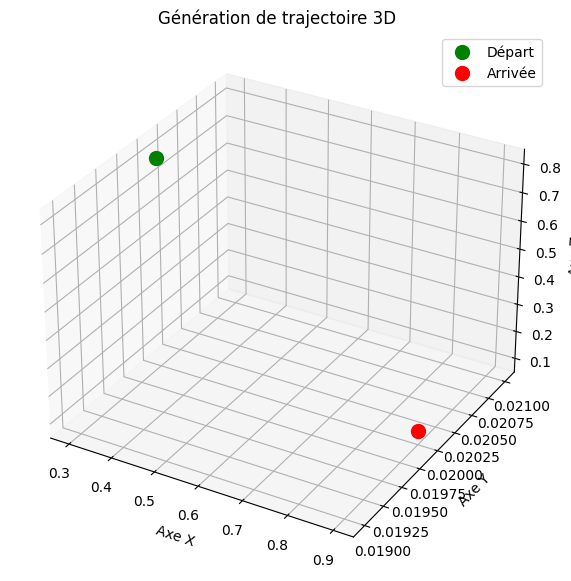

In [13]:
# --- AFFICHAGE GRAPHIQUE 3D ---
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

# Points de départ et d'arrivée
ax.scatter(depart[0][0], depart[1][0], depart[2][0], color='green', s=100, label='Départ')
ax.scatter(arrivee[0][0], arrivee[1][0], arrivee[2][0], color='red', s=100, label='Arrivée')


# Tracé de la trajectoire
#ax.plot(position['x'], position['y'], position['z'], label='Trajectoire 3D', color='b', lw=2)

ax.set_title("Génération de trajectoire 3D ")
ax.set_xlabel("Axe X")
ax.set_ylabel("Axe Y")
ax.set_zlabel("Axe Z")
ax.legend()
plt.show()


In [14]:
ori= [0,0,0,1]
qinv = list(p.calculateInverseKinematics(robot, 6,xbut, ori))
print("Xbut=",xbut)
print(qinv)
robotcontrol.PositionAffiche(robot, control_joints, qinv, frame_ee)


Xbut= [0.9, 0.02, 0.1]
[-0.004256581937057147, 1.4066855562444818, 0.9076731689610424, -0.007069042734376488, -0.7474202512613468, 0.005285714927910821]
Joint position controller
Tfin= False
